# Presynaptic fixed-10 neighborhoods: five-fold morphology classification

All five folds completed **30 epochs**. Each input is seeded at an existing
**presynaptic site** and contains **10 observed embeddings selected by geodesic distance from its skeleton anchor**. The model shares a pointwise MLP
aggregation and ResNet trunk, appends the postsynaptic embedding, and trains
**five local heads across the full morphology hierarchy (13 leaf classes)**.

This notebook reads the completed reports, epoch curves, and saved all-head
predictions. It does not train models or change the database.

**Reading the results:** the held-out fold was also used to select the best
epoch, so it is not an untouched final test set. Fold means give each fold
equal weight; error bars show sample standard deviation across folds, not
confidence intervals for independent replicates. Local-head metrics are
conditioned on the **true parent**; end-to-end metrics include routing errors.
Windows use the training pipeline's per-cell membership-set deduplication.
A saved synapse ID identifies the representative of a unique window.

**Metric convention:** ordinary accuracy is omitted. Balanced accuracy
(mean recall over supported classes) is paired with **per-class precision**;
macro precision and macro F1 summarize comparisons. Precision is set to zero
when a class has no predictions, matching the trainer. Tables show predicted
counts and the number of folds with no predictions to make these cases visible.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'scripts/train_gnn.py').exists())
RUN = ROOT / 'analysis/presynaptic/latest100k_k10_full_hierarchy'
sys.path.insert(0, str(ROOT))
from data.dataset_lcpn import load_hierarchy
from gnn.metrics import balanced_accuracy, macro_precision, macro_f1, per_class_precision, per_class_recall
completion = json.loads((RUN / 'completion.json').read_text())
plan = json.loads((RUN / 'plan.json').read_text())
folds = sorted(completion['folds'], key=lambda r: r['fold'])
assert completion['complete'] and [r['fold'] for r in folds] == list(range(5))
assert all(r['completed_epochs'] == 30 for r in folds)
manifests = {i: json.loads((RUN / 'manifests' / f'fold{i}.json').read_text()) for i in range(5)}
hierarchy = load_hierarchy(manifests[0])
levels = completion['hierarchy']['level_classes']
heads = completion['hierarchy']['local_heads']
assert hierarchy.level_classes == levels and len(heads) == 5
leaf_names = levels[-1]
COLORS = plt.get_cmap('tab10').colors
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 12})
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
def class_precision_table(matrices, names):
    rows = []
    for fold, matrix in enumerate(matrices):
        matrix = np.asarray(matrix)
        precision = per_class_precision(matrix)
        recall = per_class_recall(matrix)
        for i, name in enumerate(names):
            rows.append({'Fold': fold, 'Class': name, 'Precision': precision[i],
                         'Recall': recall[i], 'True count': int(matrix[i].sum()),
                         'Predicted count': int(matrix[:, i].sum()),
                         'No predictions': int(matrix[:, i].sum() == 0)})
    return pd.DataFrame(rows).groupby('Class', sort=False).agg(
        precision_mean=('Precision', 'mean'), precision_fold_SD=('Precision', 'std'),
        recall_mean=('Recall', 'mean'), recall_fold_SD=('Recall', 'std'),
        true_count=('True count', 'sum'), predicted_count=('Predicted count', 'sum'),
        folds_without_predictions=('No predictions', 'sum'))
def predictions_path(fold):
    return RUN / 'all_lcpn_predictions' / f'fold{fold}.parquet'
def checkpoint_path(record):
    # Prefer the current checkout when moved between lab mount aliases.
    suffix = str(record['checkpoint']).split('/results/', 1)[1]
    return ROOT / 'results' / suffix
for record in folds:
    assert pq.ParquetFile(predictions_path(record['fold'])).metadata.num_rows == record['classified_windows']
neighborhood = (f"K={plan['k_observed']} observed embeddings" if plan.get('k_observed') is not None
                else f"{completion['window_nm'] / 1000:g} µm geodesic radius")
display(pd.Series({'Neighborhood': neighborhood,
                   'Cells': plan['cells'], 'Folds': len(folds),
                   'Epochs per fold': 30, 'Learned local heads': len(heads),
                   'Leaf classes': len(leaf_names),
                   'Classified unique windows': completion['classified_windows']}).to_frame('Value'))

,Value
Neighborhood,K=10 observed embeddings
Cells,2029
Folds,5
Epochs per fold,30
Learned local heads,5
Leaf classes,13
Classified unique windows,1608393


## Hierarchy and local classifiers

Each branching parent has a separate learned output head. Unary branches
(including the neuron-only root) pass through deterministically. Every head's
logits are saved for every window, including heads outside its predicted path.

In [2]:
head_table = pd.DataFrame([{'Head': i, 'Parent': h['parent_name'],
                            'Decision level': h['child_level'],
                            'Children': ', '.join(h['children'])} for i, h in enumerate(heads)])
display(head_table.set_index('Head'))
display(pd.DataFrame({'Level': range(len(levels)), 'Classes': [', '.join(x) for x in levels]}).set_index('Level'))

,Parent,Decision level,Children
Head,,,
0,neuron,1,"excitatory, inhibitory"
1,excitatory,2,"pyramidal, thalamocortical"
2,inhibitory,2,"BasketFam, BipFam, MartFam, NglFam"
3,pyramidal,3,"ET, IT, NP, corticothalamic"
4,IT,4,"L2IT, L3IT, L4IT, L5IT, L6IT"


,Classes
Level,
0,neuron
1,"excitatory, inhibitory"
2,"BasketFam, BipFam, MartFam, NglFam, pyramidal, thalamocortical"
3,"BasketFam, BipFam, ET, IT, MartFam, NP, NglFam, corticothalamic, thalamocort..."
4,"BasketFam, BipFam, L2IT, L3IT, L4IT, L5ET, L5IT, L5NP, L6CT, L6IT, MartFam, ..."


## Best-checkpoint performance by fold

Window metrics evaluate individual unique neighborhoods. Cell metrics are
the trainer's aggregation of predictions per cell. These tables use the
**13 leaf classes**. Best-epoch indices are zero-based.
Per-class precision for both evaluation units accompanies the aggregate scores.

,Best epoch (0-based),Held-out windows,Window balanced_accuracy,Window macro_precision,Window macro_f1,Cell balanced_accuracy,Cell macro_precision,Cell macro_f1
Fold,,,,,,,,
0,29,317787,0.6199,0.6266,0.6055,0.8001,0.8237,0.7870
1,26,328236,0.6278,0.6086,0.6053,0.8115,0.9011,0.8413
2,26,314873,0.5941,0.6526,0.6071,0.7590,0.8146,0.7751
3,26,322789,0.6300,0.6469,0.6275,0.7812,0.8107,0.7868
4,25,324708,0.5910,0.6851,0.6118,0.7701,0.8104,0.7793


,mean,fold SD
Window balanced_accuracy,0.6125,0.0187
Window macro_precision,0.6440,0.0289
Window macro_f1,0.6115,0.0094
Cell balanced_accuracy,0.7844,0.0215
Cell macro_precision,0.8321,0.0390
Cell macro_f1,0.7939,0.0270


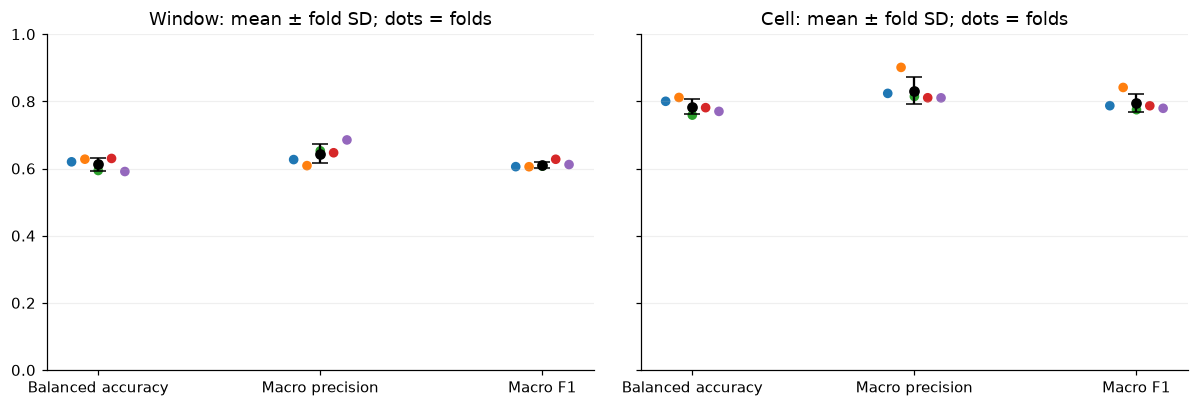

precision_mean  precision_fold_SD  recall_mean  \
Evaluation Class                                                             
Window     BasketFam                0.9437             0.0218       0.9717   
           BipFam                   0.7268             0.1029       0.7010   
           L2IT                     0.5479             0.0732       0.4521   
           L3IT                     0.5174             0.0816       0.3212   
           L4IT                     0.6652             0.0297       0.7406   
           L5ET                     0.7565             0.0789       0.6313   
           L5IT                     0.2908             0.0425       0.4581   
           L5NP                     0.2506             0.1610       0.1455   
           L6CT                     0.6480             0.1249       0.4781   
           L6IT                     0.4820             0.0543       0.5388   
           MartFam                  0.9342             0.0212       0.8414   
           NglFam                   0.6804             0.1887       0.7397   
           thalamocortical          0.9278             0.0107       0.9436   
Cell       BasketFam                0.9663             0.0231       1.0000   
           BipFam                   0.9383             0.0668       0.9198   
           L2IT                     0.8415             0.0748       0.7552   
           L3IT                     0.8091             0.1071       0.4582   
           L4IT                     0.7629             0.0745       0.9675   
           L5ET                     1.0000             0.0000       0.9236   
           L5IT                     0.7265             0.0922       0.7147   
           L5NP                     0.2000             0.4472       0.1000   
           L6CT                     0.9750             0.0425       0.7782   
           L6IT                     0.6741             0.1269       0.8292   
           MartFam                  0.9233             0.0336       0.8707   
           NglFam                   1.0000             0.0000       0.8800   
           thalamocortical          1.0000             0.0000       1.0000   

                            recall_fold_SD  true_count  predicted_count  \
Evaluation Class                                                          
Window     BasketFam                0.0051      470038           484479   
           BipFam                   0.1008       69548            67336   
           L2IT                     0.0741      104533            87081   
           L3IT                     0.0987      103257            66199   
           L4IT                     0.0414      279744           312648   
           L5ET                     0.0318       13467            11393   
           L5IT                     0.0421       69963           111142   
           L5NP                     0.1330        3679             2885   
           L6CT                     0.1029       32380            26034   
           L6IT                     0.1154       59543            65893   
           MartFam                  0.0358      316379           284509   
           NglFam                   0.0756       10189            11670   
           thalamocortical          0.0212       75673            77124   
Cell       BasketFam                0.0000         171              177   
           BipFam                   0.0597         113              111   
           L2IT                     0.1611         268              242   
           L3IT                     0.1938         219              129   
           L4IT                     0.0107         522              667   
           L5ET                     0.0773          51               47   
           L5IT                     0.0619         116              117   
           L5NP                     0.2236          10                1   
           L6CT                     0.1410         244              196   
           L6IT                     0.1299 

In [3]:
rows = []
for record in folds:
    rows.append({'Fold': record['fold'], 'Best epoch (0-based)': record['best_epoch'],
                 'Held-out windows': record['classified_windows'],
                 **{f'{unit} {metric}': record[key][metric]
                    for unit, key in [('Window', 'window_metrics'), ('Cell', 'cell_metrics')]
                    for metric in ['balanced_accuracy', 'macro_precision', 'macro_f1']}})
scores = pd.DataFrame(rows).set_index('Fold')
display(scores.round(4))
metric_columns = [c for c in scores if c.startswith(('Window ', 'Cell '))]
display(scores[metric_columns].agg(['mean', 'std']).T.rename(columns={'std': 'fold SD'}).round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, unit in zip(axes, ['Window', 'Cell']):
    for i, metric in enumerate(['balanced_accuracy', 'macro_precision', 'macro_f1']):
        values = scores[f'{unit} {metric}'].to_numpy()
        ax.errorbar(i, values.mean(), yerr=values.std(ddof=1), fmt='o', color='black', capsize=5)
        ax.scatter(i + np.linspace(-.12, .12, 5), values, c=COLORS[:5], s=28)
    ax.set_xticks(range(3), ['Balanced accuracy', 'Macro precision', 'Macro F1'])
    ax.set_title(f'{unit}: mean ± fold SD; dots = folds')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=.2)
fig.tight_layout()
plt.show()
leaf_precision = pd.concat({unit: class_precision_table(
    [record[key]['confusion_matrix'] for record in folds], leaf_names)
    for unit, key in [('Window', 'window_metrics'), ('Cell', 'cell_metrics')]},
    names=['Evaluation', 'Class'])
display(leaf_precision.round(4))
for record in folds:
    for key in ['window_metrics', 'cell_metrics']:
        actual = per_class_precision(np.asarray(record[key]['confusion_matrix']))
        np.testing.assert_allclose(actual, [record[key]['per_class_precision'][name] for name in leaf_names])

## Training curves

Curves include all 30 epochs; markers locate the selected checkpoint in
each fold. Validation here is the same cell-held-out fold reported above.

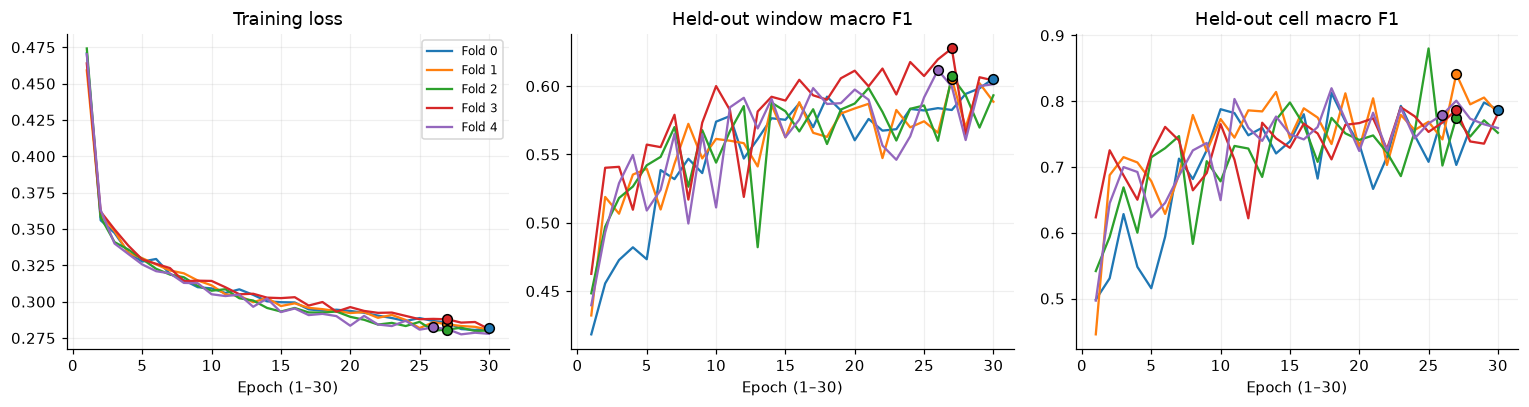

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for record in folds:
    frame = pd.read_csv(checkpoint_path(record).parent / 'epoch_metrics.csv')
    assert set(frame.epoch) == set(range(30))
    for ax, metric, title in zip(axes, ['train_loss', 'window_macro_f1', 'cell_macro_f1'],
                                 ['Training loss', 'Held-out window macro F1', 'Held-out cell macro F1']):
        ax.plot(frame.epoch + 1, frame[metric], color=COLORS[record['fold']], label=f"Fold {record['fold']}")
        best = frame.loc[frame.epoch == record['best_epoch']].iloc[-1]
        ax.scatter(best.epoch + 1, best[metric], color=COLORS[record['fold']], edgecolor='black', s=40, zorder=3)
        ax.set(title=title, xlabel='Epoch (1–30)')
        ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## End-to-end predictions at each hierarchy level

We collapse the saved **window-level leaf confusion matrices** to each
ancestor level. This measures the full predicted route, including upstream
errors. It is not conditional local-head performance. The constant neuron-only
root is omitted from the plot.
Per-class precision is reported separately for each level's class vocabulary.

balanced_accuracy         macro_precision         macro_f1  \
                           mean     std            mean     std     mean   
Level Classes                                                              
0     1                  1.0000  0.0000          1.0000  0.0000   1.0000   
1     2                  0.9730  0.0011          0.9716  0.0012   0.9721   
2     6                  0.8620  0.0247          0.8606  0.0343   0.8564   
3     9                  0.7125  0.0337          0.7544  0.0443   0.7187   
4     13                 0.6125  0.0187          0.6440  0.0289   0.6115   

                       
                  std  
Level Classes          
0     1        0.0000  
1     2        0.0011  
2     6        0.0231  
3     9        0.0100  
4     13       0.0094

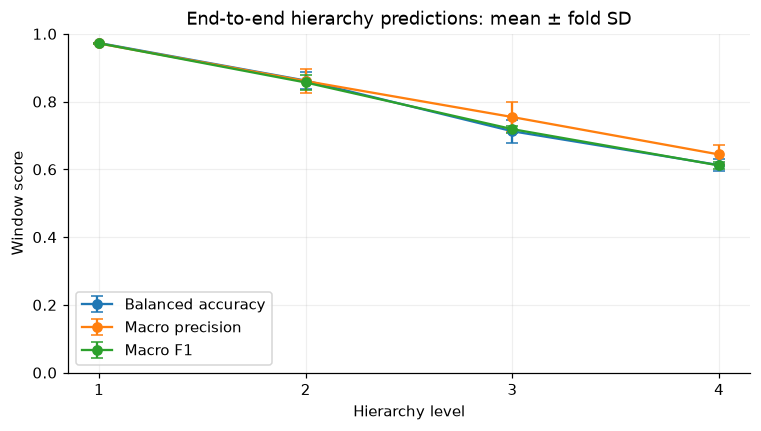

precision_mean  precision_fold_SD  recall_mean  \
Level Class                                                             
1     excitatory               0.9587             0.0055       0.9822   
      inhibitory               0.9844             0.0045       0.9637   
2     BasketFam                0.9437             0.0218       0.9717   
      BipFam                   0.7268             0.1029       0.7010   
      MartFam                  0.9342             0.0212       0.8414   
      NglFam                   0.6804             0.1887       0.7397   
      pyramidal                0.9506             0.0063       0.9744   
      thalamocortical          0.9278             0.0107       0.9436   
3     BasketFam                0.9437             0.0218       0.9717   
      BipFam                   0.7268             0.1029       0.7010   
      ET                       0.7565             0.0789       0.6313   
      IT                       0.9213             0.0120       0.9601   
      MartFam                  0.9342             0.0212       0.8414   
      NP                       0.2506             0.1610       0.1455   
      NglFam                   0.6804             0.1887       0.7397   
      corticothalamic          0.6480             0.1249       0.4781   
      thalamocortical          0.9278             0.0107       0.9436   
4     BasketFam                0.9437             0.0218       0.9717   
      BipFam                   0.7268             0.1029       0.7010   
      L2IT                     0.5479             0.0732       0.4521   
      L3IT                     0.5174             0.0816       0.3212   
      L4IT                     0.6652             0.0297       0.7406   
      L5ET                     0.7565             0.0789       0.6313   
      L5IT                     0.2908             0.0425       0.4581   
      L5NP                     0.2506             0.1610       0.1455   
      L6CT                     0.6480             0.1249       0.4781   
      L6IT                     0.4820             0.0543       0.5388   
      MartFam                  0.9342             0.0212       0.8414   
      NglFam                   0.6804             0.1887       0.7397   
      thalamocortical          0.9278             0.0107       0.9436   

                       recall_fold_SD  true_count  predicted_count  \
Level Class                                                          
1     excitatory               0.0050      742239           760399   
      inhibitory               0.0045      866154           847994   
2     BasketFam                0.0051      470038           484479   
      BipFam                   0.1008       69548            67336   
      MartFam                  0.0358      316379           284509   
      NglFam                   0.0756       10189            11670   
      pyramidal                0.0065      666566           683275   
      thalamocortical          0.0212       75673            77124   
3     BasketFam                0.0051      470038           484479   
      BipFam                   0.1008       69548            67336   
      ET                       0.0318       13467            11393   
      IT                       0.0165      617040           642963   
      MartFam                  0.0358      316379           284509   
      NP                       0.1330        3679             2885   
      NglFam                   0.0756       10189            11670   
      corticothalamic          0.1029       32380            26034   
      thalamocortical          0.0212       75673            77124   
4     BasketFam                0.0051      470038           484479   
      BipFam                   0.1008       69548            67336   
      L2IT                     0.0741      104533            87081   
      L3IT                     0.0987      103257            66199   
      L4IT                     0.0414      279744           312648   
      

In [5]:
def matrix_metrics(matrix):
    matrix = np.asarray(matrix)
    return {'balanced_accuracy': balanced_accuracy(matrix),
            'macro_precision': macro_precision(matrix), 'macro_f1': macro_f1(matrix)}
level_matrices = {}
level_rows = []
for record in folds:
    leaf = np.asarray(record['window_metrics']['confusion_matrix'])
    assert leaf.shape == (len(leaf_names), len(leaf_names))
    for level, names in enumerate(levels):
        ancestors = np.array([hierarchy.level_maps[level][hierarchy.label_paths[name][level]] for name in leaf_names])
        collapsed = np.zeros((len(names), len(names)), dtype=np.int64)
        np.add.at(collapsed, (ancestors[:, None], ancestors[None, :]), leaf)
        assert collapsed.sum() == record['classified_windows']
        level_matrices[(record['fold'], level)] = collapsed
        level_rows.append({'Fold': record['fold'], 'Level': level, 'Classes': len(names), **matrix_metrics(collapsed)})
    assert np.isclose(matrix_metrics(leaf)['macro_f1'], record['window_metrics']['macro_f1'])
level_scores = pd.DataFrame(level_rows)
display(level_scores.groupby(['Level', 'Classes'])[['balanced_accuracy', 'macro_precision', 'macro_f1']].agg(['mean', 'std']).round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for metric, label in [('balanced_accuracy', 'Balanced accuracy'), ('macro_precision', 'Macro precision'), ('macro_f1', 'Macro F1')]:
    grouped = level_scores.query('Level > 0').groupby('Level')[metric].agg(['mean', 'std'])
    ax.errorbar(grouped.index, grouped['mean'], yerr=grouped['std'], marker='o', capsize=4, label=label)
ax.set(xticks=range(1, len(levels)), xlabel='Hierarchy level', ylabel='Window score', ylim=(0, 1),
       title='End-to-end hierarchy predictions: mean ± fold SD')
ax.legend()
ax.grid(alpha=.2)
plt.show()
level_precision = pd.concat({level: class_precision_table(
    [level_matrices[(fold, level)] for fold in range(5)], names)
    for level, names in enumerate(levels) if level > 0}, names=['Level', 'Class'])
display(level_precision.round(4))

## Every local head, conditioned on its true parent

A head is evaluated on windows whose true label lies under that parent,
regardless of upstream predictions. This separates local discrimination
from routing errors. Support counts sum across the disjoint held-out folds.
Precision here is conditional on the true parent, just like the head's
balanced accuracy; it is not end-to-end precision for that class.

,held_out_support,balanced_accuracy,balanced_accuracy_fold_SD,macro_precision,macro_precision_fold_SD,macro_F1,macro_F1_fold_SD
Parent,,,,,,,
neuron,1608393,0.9730,0.0011,0.9715,0.0012,0.9721,0.0011
excitatory,742239,0.9699,0.0101,0.9670,0.0040,0.9684,0.0063
inhibitory,866154,0.8538,0.0234,0.8208,0.0466,0.8292,0.0311
pyramidal,666566,0.5775,0.0593,0.7071,0.0928,0.6074,0.0256
IT,617040,0.5298,0.0210,0.5514,0.0152,0.5237,0.0133


precision_mean  precision_fold_SD  recall_mean  \
True parent Child class                                                       
neuron      excitatory               0.9587             0.0055       0.9822   
            inhibitory               0.9844             0.0045       0.9637   
excitatory  pyramidal                0.9942             0.0020       0.9931   
            thalamocortical          0.9398             0.0070       0.9467   
inhibitory  BasketFam                0.9464             0.0208       0.9748   
            BipFam                   0.7214             0.0945       0.8344   
            MartFam                  0.9409             0.0234       0.8639   
            NglFam                   0.6747             0.1836       0.7421   
pyramidal   ET                       0.8433             0.0929       0.6897   
            IT                       0.9645             0.0074       0.9821   
            NP                       0.3233             0.2429       0.1518   
            corticothalamic          0.6973             0.1264       0.4864   
IT          L2IT                     0.5822             0.0721       0.4633   
            L3IT                     0.5394             0.0842       0.3243   
            L4IT                     0.6984             0.0315       0.7543   
            L5IT                     0.3196             0.0388       0.4800   
            L6IT                     0.6172             0.0711       0.6270   

                             recall_fold_SD  true_count  predicted_count  \
True parent Child class                                                    
neuron      excitatory               0.0050      742239           760400   
            inhibitory               0.0045      866154           847993   
excitatory  pyramidal                0.0014      666566           665856   
            thalamocortical          0.0208       75673            76383   
inhibitory  BasketFam                0.0052      470038           484610   
            BipFam                   0.1038       69548            79664   
            MartFam                  0.0379      316379           290144   
            NglFam                   0.0757       10189            11736   
pyramidal   ET                       0.0485       13467            11198   
            IT                       0.0155      617040           628206   
            NP                       0.1400        3679             2657   
            corticothalamic          0.1054       32380            24505   
IT          L2IT                     0.0690      104533            83672   
            L3IT                     0.1002      103257            64092   
            L4IT                     0.0436      279744           303389   
            L5IT                     0.0435       69963           105635   
            L6IT                     0.0942       59543            60252   

                             folds_without_predictions  
True parent Child class                                 
neuron      excitatory                               0  
            inhibitory                               0  
excitatory  pyramidal                                0  
            thalamocortical                          0  
inhibitory  BasketFam                                0  
            BipFam                                   0  
            MartFam                                  0  
            NglFam                                   0  
pyramidal   ET                                       0  
            IT                                       0  
            NP                                       0  
            corticothalamic                          0  
IT          L2IT                                     0  
            L3IT                                     0  
            L4IT                                     0  
            L5IT                                     0  
            L6IT                                     0

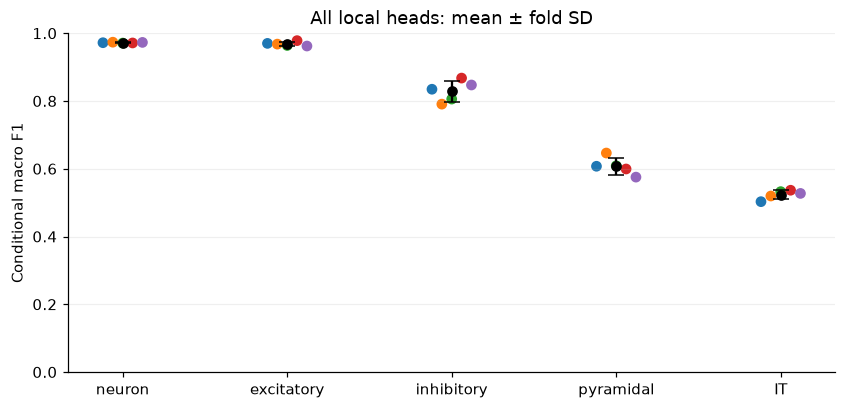

In [6]:
head_rows = []
head_matrices = {}
for record in folds:
    for i, metrics in enumerate(record['local_head_metrics']):
        assert metrics['parent'] == heads[i]['parent_name'] and metrics['children'] == heads[i]['children']
        matrix = np.asarray(metrics['confusion_matrix'])
        assert matrix.sum() == metrics['support']
        head_matrices[(record['fold'], i)] = matrix
        head_rows.append({'Fold': record['fold'], 'Head': i, 'Parent': metrics['parent'],
                          'Support': metrics['support'], **matrix_metrics(matrix)})
head_scores = pd.DataFrame(head_rows)
display(head_scores.groupby('Parent', sort=False).agg(
    held_out_support=('Support', 'sum'), balanced_accuracy=('balanced_accuracy', 'mean'),
    balanced_accuracy_fold_SD=('balanced_accuracy', 'std'),
    macro_precision=('macro_precision', 'mean'), macro_precision_fold_SD=('macro_precision', 'std'),
    macro_F1=('macro_f1', 'mean'), macro_F1_fold_SD=('macro_f1', 'std')).round(4))
head_precision = pd.concat({head['parent_name']: class_precision_table(
    [head_matrices[(fold, i)] for fold in range(5)], head['children'])
    for i, head in enumerate(heads)}, names=['True parent', 'Child class'])
display(head_precision.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
for i, head in enumerate(heads):
    group = head_scores[head_scores.Head == i]
    values = group.macro_f1.to_numpy()
    ax.errorbar(i, values.mean(), yerr=values.std(ddof=1), fmt='o', color='black', capsize=5)
    ax.scatter(i + np.linspace(-.12, .12, 5), values, c=COLORS[:5])
ax.set(xticks=range(len(heads)), xticklabels=[h['parent_name'] for h in heads],
       ylabel='Conditional macro F1', ylim=(0, 1), title='All local heads: mean ± fold SD')
ax.grid(axis='y', alpha=.2)
plt.show()

## Confusion matrices and per-class precision

Rows are true classes and columns are predictions. Each fold is normalized
by its own row support **before** taking the equal-weight mean. Unsupported
rows are omitted from that row's mean rather than counted as zero recall.
These row-normalized matrices show recall; the precision panels below use
predicted-class counts as their denominator.

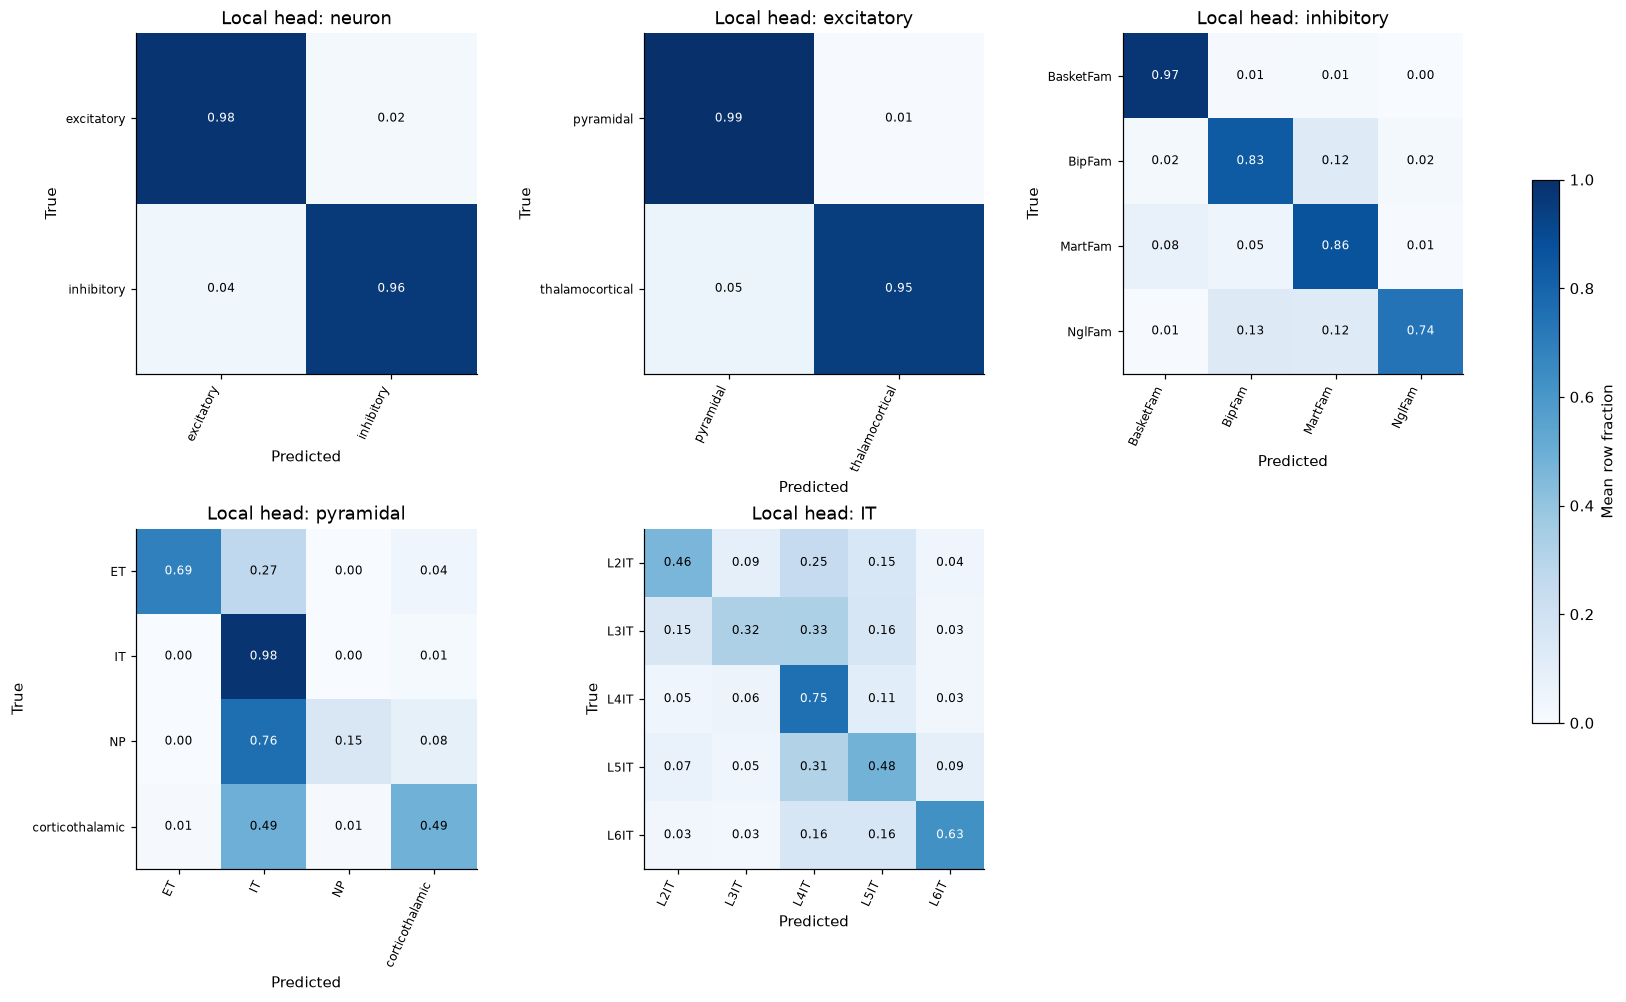

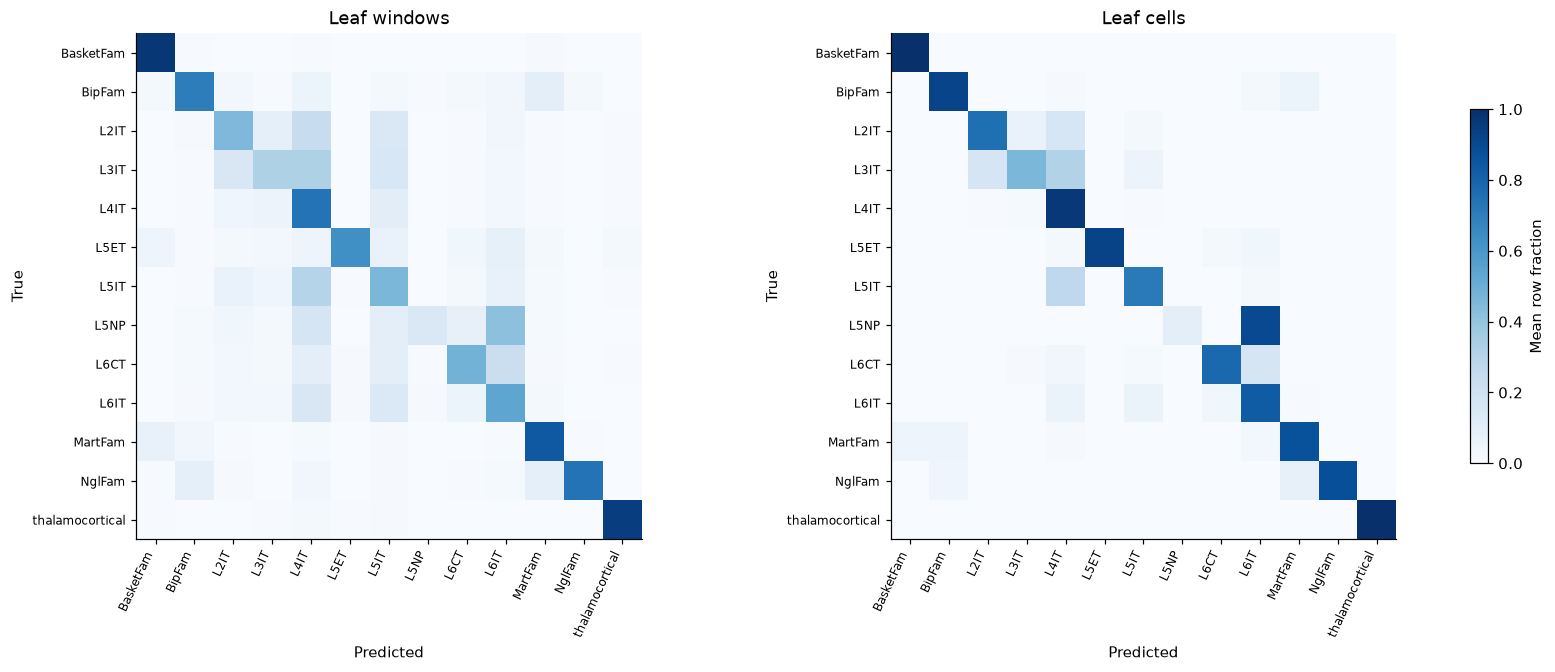

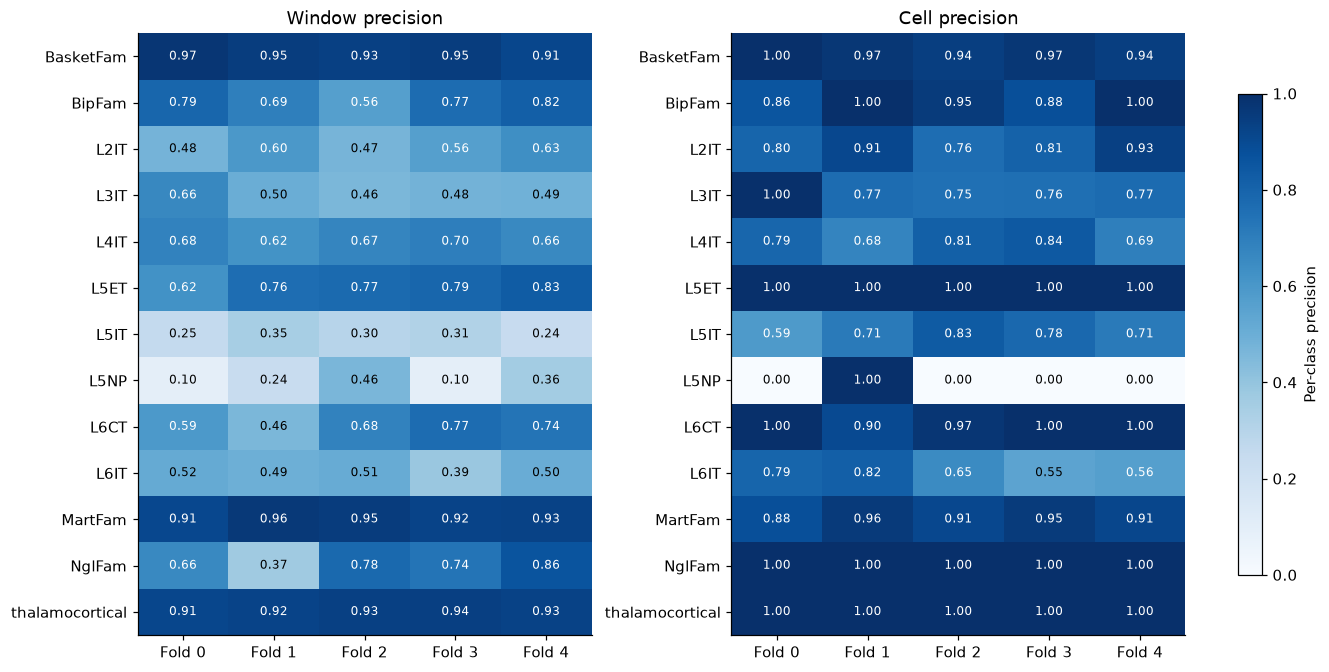

In [7]:
def mean_normalized(matrices):
    normalized = []
    for matrix in matrices:
        matrix = np.asarray(matrix, dtype=float)
        support = matrix.sum(1, keepdims=True)
        normalized.append(np.divide(matrix, support, out=np.full_like(matrix, np.nan), where=support > 0))
    return np.nanmean(normalized, axis=0)
def draw_matrix(ax, matrix, names, title, annotate=False):
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues')
    ax.set(xticks=range(len(names)), yticks=range(len(names)), xticklabels=names, yticklabels=names,
           xlabel='Predicted', ylabel='True', title=title)
    plt.setp(ax.get_xticklabels(), rotation=65, ha='right', fontsize=8)
    plt.setp(ax.get_yticklabels(), fontsize=8)
    if annotate:
        for (i, j), value in np.ndenumerate(matrix):
            if np.isfinite(value):
                ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
                        color='white' if value > .55 else 'black')
    return image
fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout='constrained')
for i, head in enumerate(heads):
    matrix = mean_normalized([head_matrices[(f, i)] for f in range(5)])
    image = draw_matrix(axes.flat[i], matrix, head['children'], f"Local head: {head['parent_name']}", True)
axes.flat[-1].axis('off')
fig.colorbar(image, ax=list(axes.flat[:-1]), shrink=.65, label='Mean row fraction')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout='constrained')
for ax, key, title in zip(axes, ['window_metrics', 'cell_metrics'], ['Leaf windows', 'Leaf cells']):
    matrix = mean_normalized([record[key]['confusion_matrix'] for record in folds])
    image = draw_matrix(ax, matrix, leaf_names, title)
fig.colorbar(image, ax=axes.tolist(), shrink=.7, label='Mean row fraction')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
for ax, key, title in zip(axes, ['window_metrics', 'cell_metrics'], ['Window precision', 'Cell precision']):
    precision = pd.DataFrame({f"Fold {r['fold']}": r[key]['per_class_precision'] for r in folds}).reindex(leaf_names)
    image = ax.imshow(precision.to_numpy(), vmin=0, vmax=1, cmap='Blues', aspect='auto')
    ax.set(xticks=range(5), xticklabels=precision.columns, yticks=range(len(leaf_names)),
           yticklabels=leaf_names, title=title)
    for (i, j), value in np.ndenumerate(precision.to_numpy()):
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
                color='white' if value > .55 else 'black')
fig.colorbar(image, ax=axes.tolist(), shrink=.8, label='Per-class precision')
plt.show()

## Number of embeddings per window

This reads only the `n_embeddings` column, in batches, from the saved
predictions. Counts describe eligible, deduplicated held-out windows rather
than every raw synapse. The ten-embedding line is a reference to the previous
selection rule, not a matched model-performance comparison.

,Value
Mean embeddings,10.0
10th percentile,10.0
Median,10.0
90th percentile,10.0
Maximum,10.0
Fraction below 10,0.0


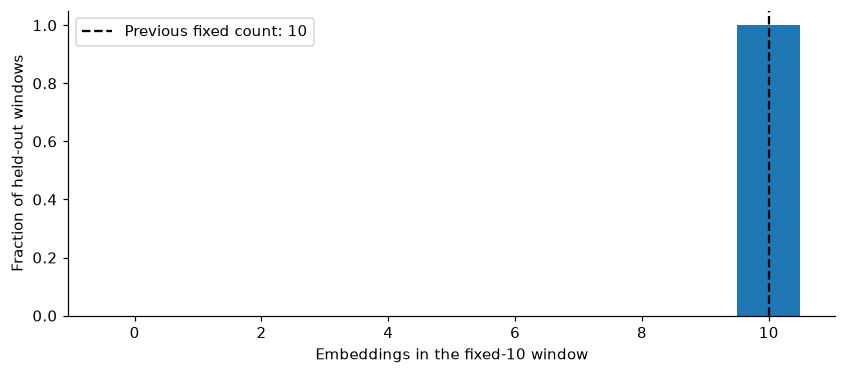

In [8]:
size_counts = {}
for record in folds:
    histogram = np.zeros(plan['maximum_embeddings'] + 1, np.int64)
    for batch in pq.ParquetFile(predictions_path(record['fold'])).iter_batches(columns=['n_embeddings'], batch_size=65536):
        sizes = batch.column(0).to_numpy()
        assert (sizes > 0).all() and sizes.max() <= plan['maximum_embeddings']
        histogram += np.bincount(sizes, minlength=len(histogram))
    assert histogram.sum() == record['classified_windows']
    size_counts[record['fold']] = histogram
counts = sum(size_counts.values())
x = np.arange(len(counts))
quantiles = x[np.searchsorted(np.cumsum(counts), np.array([.1, .5, .9]) * counts.sum())]
display(pd.Series({'Mean embeddings': np.dot(x, counts) / counts.sum(),
                   '10th percentile': quantiles[0], 'Median': quantiles[1],
                   '90th percentile': quantiles[2], 'Maximum': x[counts > 0].max(),
                   'Fraction below 10': counts[:10].sum() / counts.sum()}).to_frame('Value'))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x, counts / counts.sum(), width=1, color=COLORS[0])
ax.axvline(10, color='black', linestyle='--', label='Previous fixed count: 10')
ax.set(xlabel='Embeddings in the fixed-10 window', ylabel='Fraction of held-out windows')
ax.legend()
plt.show()

## Inspect saved logits from every head

Edit `FOLD`, `N_ROWS` and `ROW` below. The preview takes the first rows for
inspection, **not a representative random sample**. Logits are local raw
scores; the associated softmax probabilities are conditional on the head's
parent. Do not softmax logits from different heads together. Joint
probabilities multiply the relevant probabilities along the hierarchy.
An off-path head still has logits, but its conditional decision is not a
claim that the window belongs to that parent.

In [9]:
FOLD = 0
N_ROWS = 8
ROW = 0
assert 0 <= FOLD < 5 and 0 <= ROW < N_ROWS
sample = next(pq.ParquetFile(predictions_path(FOLD)).iter_batches(batch_size=N_ROWS)).to_pandas()
preview = sample[['root_id', 'synapse_id', 'window_row', 'n_embeddings']].copy()
preview['true_leaf'] = [manifests[FOLD]['cells'][str(int(rid))]['cell_type'] for rid in sample.root_id]
preview['predicted_leaf'] = [leaf_names[int(path[-1])] for path in sample.top_down_predictions]
display(preview)
row = sample.iloc[ROW]
truth = hierarchy.label_paths[preview.iloc[ROW].true_leaf]
local_rows = []
for i, head in enumerate(heads):
    logits = np.asarray(row[f'head_{i}_logits'])
    probabilities = np.asarray(row[f'head_{i}_probabilities'])
    assert len(logits) == head['n_children'] and np.isclose(probabilities.sum(), 1, atol=1e-6)
    on_path = head['parent_level'] < 0 or truth[head['parent_level']] == head['parent_name']
    for child, logit, probability in zip(head['children'], logits, probabilities):
        local_rows.append({'Head parent': head['parent_name'], 'On true parent path': on_path,
                           'Child': child, 'Logit': float(logit), 'Conditional probability': float(probability)})
display(pd.DataFrame(local_rows).set_index(['Head parent', 'Child']).round(5))
joint_rows = []
for level, names in enumerate(levels):
    probabilities = np.asarray(row[f'level_{level}_joint_probabilities'])
    assert np.isclose(probabilities.sum(), 1, atol=1e-5)
    selected = int(row.top_down_predictions[level])
    for i, (name, probability) in enumerate(zip(names, probabilities)):
        joint_rows.append({'Level': level, 'Class': name, 'Joint probability': float(probability),
                           'Top-down selection': i == selected})
display(pd.DataFrame(joint_rows).set_index(['Level', 'Class']).round(5))

,root_id,synapse_id,window_row,n_embeddings,true_leaf,predicted_leaf
0,864691134887444986,170338832,0,10,NglFam,NglFam
1,864691134887444986,185839131,1,10,NglFam,NglFam
2,864691134887444986,233361721,2,10,NglFam,NglFam
3,864691134887444986,171354532,3,10,NglFam,NglFam
4,864691134887444986,185511685,5,10,NglFam,NglFam
5,864691134887444986,202647217,6,10,NglFam,NglFam
6,864691134887444986,157533101,7,10,NglFam,NglFam
7,864691134887444986,160833627,8,10,NglFam,NglFam


On true parent path    Logit  \
Head parent Child                                           
neuron      excitatory                      True -1.12527   
            inhibitory                      True  2.64691   
excitatory  pyramidal                      False  1.67833   
            thalamocortical                False -1.67062   
inhibitory  BasketFam                       True -2.98849   
            BipFam                          True  1.25185   
            MartFam                         True -1.47655   
            NglFam                          True  2.83453   
pyramidal   ET                             False -2.27263   
            IT                             False  1.38133   
            NP                             False -3.09088   
            corticothalamic                False -0.33646   
IT          L2IT                           False  0.58352   
            L3IT                           False -0.02792   
            L4IT                           False  0.91313   
            L5IT                           False -0.07783   
            L6IT                           False -0.89656   

                             Conditional probability  
Head parent Child                                     
neuron      excitatory                       0.02248  
            inhibitory                       0.97752  
excitatory  pyramidal                        0.96607  
            thalamocortical                  0.03393  
inhibitory  BasketFam                        0.00242  
            BipFam                           0.16813  
            MartFam                          0.01098  
            NglFam                           0.81846  
pyramidal   ET                               0.02128  
            IT                               0.82185  
            NP                               0.00939  
            corticothalamic                  0.14749  
IT          L2IT                             0.27198  
            L3IT                             0.14757  
            L4IT                             0.37817  
            L5IT                             0.14038  
            L6IT                             0.06191

Joint probability  Top-down selection
Level Class                                                 
0     neuron                     1.00000                True
1     excitatory                 0.02248               False
      inhibitory                 0.97752                True
2     BasketFam                  0.00237               False
      BipFam                     0.16435               False
      MartFam                    0.01074               False
      NglFam                     0.80006                True
      pyramidal                  0.02172               False
      thalamocortical            0.00076               False
3     BasketFam                  0.00237               False
      BipFam                     0.16435               False
      ET                         0.00046               False
      IT                         0.01785               False
      MartFam                    0.01074               False
      NP                         0.00020               False
      NglFam                     0.80006                True
      corticothalamic            0.00320               False
      thalamocortical            0.00076               False
4     BasketFam                  0.00237               False
      BipFam                     0.16435               False
      L2IT                       0.00486               False
      L3IT                       0.00263               False
      L4IT                       0.00675               False
      L5ET                       0.00046               False
      L5IT                       0.00251               False
      L5NP                       0.00020               False
      L6CT                       0.00320               False
      L6IT                       0.00111               False
      MartFam                    0.01074               False
      NglFam                     0.80006                True
      thalamocortical            0.00076               False

## Files and provenance

`completion.json` records verified checkpoint hashes and coverage.
`all_lcpn_predictions/fold*.json` records head ordering, score semantics and
Parquet hashes. Source anchor eligibility was preserved per site, including
historical 2 µm/5 µm differences documented in the original 20 µm run's
`source_anchor_audit.json` and the experiment notes.
Source soma geometry, folds and newest 100k SegCLR features were retained:
the 5 µm cut applies where present; explicitly soma-free records retain their
full skeleton. The finer hierarchy changes the label task from the earlier
six-class run, so its leaf scores should not be compared directly to that run.

See [the experiment and upstream pipeline notes](../../../docs/presynaptic_geodesic20um.md).

In [10]:
display(pd.DataFrame([{'Fold': r['fold'], 'Checkpoint': str(checkpoint_path(r)),
                       'Predictions': str(predictions_path(r['fold'])),
                       'Rows': r['classified_windows']} for r in folds]).set_index('Fold'))
display(pd.Series({'Embedding run': plan['feature_run_id'],
                   'SegCLR checkpoint SHA256': plan['feature_checkpoint_sha256'],
                   'Anchor policy': plan['anchor_match_policy'],
                   'Completion plan SHA256': completion['plan_sha256']}).to_frame('Provenance'))

,Checkpoint,Predictions,Rows
Fold,,,
0,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,317787
1,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,328236
2,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,314873
3,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,322789
4,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/results/presynaptic_la...,/orcd/home/002/jcbliao/rotation/segclr/gnn_classifier/analysis/presynaptic/l...,324708


,Provenance
Embedding run,resnet50_1280b_slab1280_50um_mac_partial_aug_2_style_bf16_100k__20261022_140504
SegCLR checkpoint SHA256,826eebf68fdd47e979385c8f401825a8c9f4f2ea2c838794066f5b906a080897
Anchor policy,"preserve source per-site eligibility, including historical 2um and 5um cutoffs"
Completion plan SHA256,61420eb946f0098ddf6e78bc6255b4c6bcc9ad6670be95dfa287adad44ad6258


## segclr-db export

The receipt below records the verified export of these held-out windows,
with one prediction run per fold and raw logits from all five local heads.
Database `root_id` is the postsynaptic target; `subject_root_id` is the
classified presynaptic cell. Node IDs refer to its canonical CAVE skeleton.

Database logits are stored in hierarchy-level class order. Apply softmax
separately over each head's `child_global_indices`, never over a whole level.
Full conditional and joint probabilities remain in the shared artifact
bundle's `all_lcpn_predictions/fold*.parquet` files. The export does not run
inference on additional synapses or integrate the production predictor.

In [11]:
receipt_path = RUN / 'segclr_db_export/receipt.json'
if receipt_path.exists():
    export = json.loads(receipt_path.read_text())
    assert export['complete'] and len(export['folds']) == 5
    display(pd.Series({key: export[key] for key in
                       ('database_root', 'dataset', 'shared_bundle', 'predictions',
                        'level_logit_rows', 'completed_utc')}).to_frame('Verified export'))
    display(pd.DataFrame(export['folds']).set_index('fold'))
else:
    print('No completed segclr-db export receipt is present.')

,Verified export
database_root,/orcd/compute/sdorkenw/001/segclr-db
dataset,microns
shared_bundle,/orcd/compute/sdorkenw/001/jcbliao/segclr_workflows/latest100k_k10_full_hier...
predictions,1608393
level_logit_rows,8041965
completed_utc,2026-10-26T16:44:54.004411+00:00


,prediction_run_id,predictions,level_logit_rows,exact_roundtrip_verified,worker_pid
fold,,,,,
0,presynaptic_k10_full_lcpn_fold0_61420eb946f0__20261026_164234.checkpoint_bes...,317787,1588935,True,1006808
1,presynaptic_k10_full_lcpn_fold1_61420eb946f0__20261026_164234.checkpoint_bes...,328236,1641180,True,1006806
2,presynaptic_k10_full_lcpn_fold2_61420eb946f0__20261026_164234.checkpoint_bes...,314873,1574365,True,1006807
3,presynaptic_k10_full_lcpn_fold3_61420eb946f0__20261026_164234.checkpoint_bes...,322789,1613945,True,1006802
4,presynaptic_k10_full_lcpn_fold4_61420eb946f0__20261026_164234.checkpoint_bes...,324708,1623540,True,1006805
